<b>ML Experiment 2: Implementation of Multiple Linear Regression</b><br><br><b>Aim:</b> Predict commercial building daily energy consumption (kWh) from floor area, occupancy, cooling degree days, equipment load, and insulation score.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
rng = np.random.default_rng(204)
rows = 280

floor_area = rng.uniform(180, 1450, rows)
occupants = rng.integers(12, 165, rows)
cooling_deg = rng.uniform(2.0, 24.0, rows)
equip_kw = rng.uniform(8.0, 75.0, rows)
insulation = rng.uniform(1.0, 10.0, rows)

daily_kwh = (
    42.0
    + 0.38 * floor_area
    + 1.65 * occupants
    + 8.40 * cooling_deg
    + 4.95 * equip_kw
    - 11.20 * insulation
    + rng.normal(0.0, 18.5, rows)
)

energy_df = pd.DataFrame({
    "Floor_Area_SqM": np.round(floor_area, 1),
    "Occupants": occupants,
    "Cooling_Deg_Days": np.round(cooling_deg, 2),
    "Equipment_Load_kW": np.round(equip_kw, 2),
    "Insulation_Score": np.round(insulation, 2),
    "Daily_Energy_kWh": np.round(daily_kwh, 2),
})

print("Commercial Building Energy Dataset:")
print(energy_df.head(6).to_string(index=False))

predictors = [
    "Floor_Area_SqM",
    "Occupants",
    "Cooling_Deg_Days",
    "Equipment_Load_kW",
    "Insulation_Score",
]
x_mat = energy_df[predictors]

Commercial Building Energy Dataset:
 Floor_Area_SqM  Occupants  Cooling_Deg_Days  Equipment_Load_kW  Insulation_Score  Daily_Energy_kWh
          861.3         98             21.00              73.03              9.27            937.97
         1211.2        117              8.40              46.03              4.35            937.50
          965.6         79              6.75              30.85              8.09            634.25
          465.4        138             10.44              65.99              3.98            793.71
          193.1         24             18.71              16.28              8.85            255.85
          436.2         72             18.94              31.00              2.43            606.79


In [3]:
y_vec = energy_df["Daily_Energy_kWh"]

x_tr, x_te, y_tr, y_te = train_test_split(x_mat, y_vec, test_size=0.2, random_state=29)

mlr = LinearRegression()
mlr.fit(x_tr, y_tr)

tr_pred = mlr.predict(x_tr)
te_pred = mlr.predict(x_te)

r2_te = r2_score(y_te, te_pred)
n_te, p_dim = x_te.shape
adj_r2 = 1.0 - (1.0 - r2_te) * (n_te - 1) / (n_te - p_dim - 1)

weights_df = pd.DataFrame({
    "Predictor": predictors,
    "Beta_Weight": np.round(mlr.coef_, 4),
    "Corr_With_Energy": np.round([energy_df[c].corr(y_vec) for c in predictors], 4),
})

print(f"\nIntercept: {mlr.intercept_:.4f}")
print(weights_df.to_string(index=False))
print(f"\nTrain R2: {r2_score(y_tr, tr_pred):.4f} | Test R2: {r2_te:.4f} | Adjusted R2: {adj_r2:.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_te, te_pred)):.3f} | Test MAE: {mean_absolute_error(y_te, te_pred):.3f}")


Intercept: 31.8785
        Predictor  Beta_Weight  Corr_With_Energy
   Floor_Area_SqM       0.3835            0.7307
        Occupants       1.6827            0.3475
 Cooling_Deg_Days       8.3172            0.2240
Equipment_Load_kW       4.9956            0.4771
 Insulation_Score     -10.9339           -0.0963

Train R2: 0.9899 | Test R2: 0.9906 | Adjusted R2: 0.9896
Test RMSE: 19.536 | Test MAE: 14.558


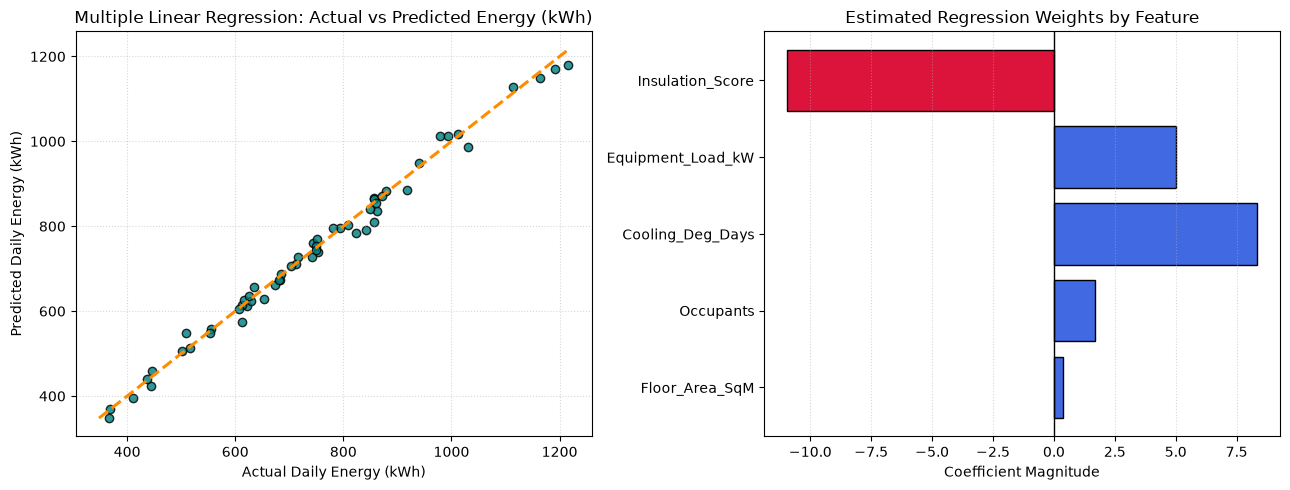

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(y_te, te_pred, color="teal", alpha=0.82, edgecolor="black")
bounds = [min(y_te.min(), te_pred.min()), max(y_te.max(), te_pred.max())]
ax[0].plot(bounds, bounds, color="darkorange", linestyle="--", linewidth=2.2)
ax[0].set_title("Multiple Linear Regression: Actual vs Predicted Energy (kWh)")
ax[0].set_xlabel("Actual Daily Energy (kWh)")
ax[0].set_ylabel("Predicted Daily Energy (kWh)")
ax[0].grid(True, linestyle=":", alpha=0.5)

bar_pal = ["royalblue" if w >= 0 else "crimson" for w in mlr.coef_]
ax[1].barh(predictors, mlr.coef_, color=bar_pal, edgecolor="black")
ax[1].axvline(0.0, color="black", linewidth=1)
ax[1].set_title("Estimated Regression Weights by Feature")
ax[1].set_xlabel("Coefficient Magnitude")
ax[1].grid(True, axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> Area, occupancy, cooling degree days, and equipment load increase energy consumption while higher insulation lowers it, achieving high R2 and Adjusted R2.